# COVID recovery and household well-being
## Phase 2 Step 0 — Clean the data and build a briefing pack

**Our question:** When employment figures improve, do people also report less financial hardship and better social well-being?

We use **Census Household Pulse Survey (HPS), 2024 Cycles 1–9**, and **BLS Local Area Unemployment Statistics (LAUS), 2019–2024**. HPS supplies financial hardship, work, income, loneliness, support, and anxiety responses. LAUS supplies the longer state employment timeline. BRFSS and the redesigned HPS successor stay outside this notebook.

This notebook does the assignment's Step 0: records cleaning decisions and affected rows, checks joins and units, compares 20 randomly selected processed records with their raw records, and makes six readable charts. The charts are an initial briefing, not a finished dashboard or a causal analysis.

**How to use it:** Read each explanation, then run the code cell below it with the ▶ button. Run in order. The first full run downloads about **660 MB of HPS archives**, plus the BLS files, unless you supply them. Use a standard CPU runtime. Allow several minutes; network and machine speed vary. No API key or paid runtime is required.

**Files already downloaded?** Keep the original HPS CSV ZIP archives intact. Each contains the respondent data, a dictionary, and replicate weights. Point the configuration below to their folder in Drive, or upload them into the runtime's `raw` folder. The small support ZIP supplied with this notebook contains the exact BLS snapshot used in our report, so our results can be repeated even if BLS revises its live files.

**Keep raw data private.** The final export contains aggregates, charts, logs, and source details. It excludes respondent records, respondent IDs, birth years, and the private spot-check table. Do not publish a notebook output that you have changed to show raw respondents.


### 1 Set up the workspace

In Colab, choose **Runtime → Change runtime type → CPU**. The cell below checks the libraries and creates folders. `raw` holds original files, `private_checks` holds the row comparison, and `results` holds the shareable outputs.

For the easiest repeatable run, upload **Step0_Colab_Support.zip** through the Files panel before running. To reuse your HPS downloads in Drive, set `USE_DRIVE = True` and change `DRIVE_PROJECT_FOLDER` to your folder. Otherwise, leave the defaults and missing files will download automatically.


In [1]:
import importlib.util, subprocess, sys
needed = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib"}
missing_packages = [package for module, package in needed.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_packages])

from pathlib import Path
import os, io, json, zipfile, hashlib, urllib.request, time, re, gc
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

USE_DRIVE = False
DRIVE_PROJECT_FOLDER = "/content/drive/MyDrive/COVID_Step0"
ALLOW_REVISED_BLS = False  # Keep False for the audited snapshot supplied in the support ZIP.
FOCUS_CYCLE = 9
FOCUS_STATE = "36"        # New York; two-digit state FIPS, for the demographic table.
TIMELINE_STATES = ["06", "36", "48"]  # California, New York, Texas; editable.
SEED = 20241109

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path(DRIVE_PROJECT_FOLDER)
else:
    BASE = Path(os.environ.get("COVID_STEP0_BASE", "/content/COVID_Step0"))
RAW = Path(os.environ.get("COVID_STEP0_RAW", str(BASE / "raw")))
RESULTS, PRIVATE = BASE / "results", BASE / "private_checks"
for directory in [RAW, RESULTS, PRIVATE, RESULTS / "charts"]:
    directory.mkdir(parents=True, exist_ok=True)

# Extract only known BLS files from the support ZIP. Never extract arbitrary paths.
support_candidates = [Path("/content/Step0_Colab_Support.zip"), BASE / "Step0_Colab_Support.zip"]
support = next((p for p in support_candidates if p.exists()), None)
if support is not None:
    with zipfile.ZipFile(support) as archive:
        for member in archive.namelist():
            filename = Path(member).name
            if member.startswith("raw/") and filename in {
                "la.data.2.AllStatesU", "la.data.3.AllStatesS", "la.series", "la.area",
                "la.measure", "la.footnote", "la.txt"}:
                destination = RAW / filename
                if not destination.exists():
                    destination.write_bytes(archive.read(member))
    print("Loaded the BLS snapshot from", support.name)

plt.rcParams.update({"figure.figsize": (10, 5.6), "figure.dpi": 110,
                     "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "text.parse_math": False})
pd.set_option("display.max_columns", 14)
print("Raw inputs:", RAW)
print("Shareable results:", RESULTS)
print("Versions:", {"python": sys.version.split()[0], "pandas": pd.__version__,
                    "numpy": np.__version__, "matplotlib": matplotlib.__version__})


Versions: {'python': '3.12.14', 'pandas': '3.0.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


### 2 Understand the variables before cleaning

An HPS raw row is one adult's response in one cycle. It is not a household followed over the whole pandemic. We use **PWEIGHT** to estimate percentages of adults. The outcome can describe the adult's household, but the percentage still refers to adults. We use all **80 person replicate weights** for sampling uncertainty.

| Data column | Meaning and valid responses | Our measure |
|---|---|---|
| `EXPNS_DIF` (question `SPN4`) | Difficulty paying usual expenses in the last 7 days: 1 not at all, 2 a little, 3 somewhat, 4 very | Financial hardship = 3 or 4 |
| `SOCIAL2` (question `SOC2`) | Feeling lonely: 1 always through 5 never | Frequent loneliness = 1 or 2 |
| `SOCIAL1` (question `SOC1`) | Receiving needed social/emotional support: 1 always through 5 never | Lack of support = 3, 4, or 5, following the CDC reporting definition |
| `ANXIOUS` | Feeling nervous/anxious/on edge in the last 2 weeks: 1 not at all through 4 nearly every day | Frequent anxiety symptoms = 3 or 4; this is not a diagnosis |
| `ANYWORK` | Worked for pay/profit in the last 7 days: 1 yes, 2 no | Work groups; no does not mean BLS unemployed |
| `INCOME` | Eight categories of **2023 household income before tax** | Under $50k; $50k–$99,999; $100k+ |
| `TBIRTH_YEAR` | Capped birth-year field | Approximate age = 2024 minus birth year; groups 18–34, 35–64, 65+ |
| `EST_ST` | State FIPS | Two-character text, including leading zero |

`-88` and `-99` are not valid answers to these single-choice outcome questions. We exclude them from that outcome's denominator while retaining the respondent for other measures. We do not apply that rule blindly to checkbox questions such as SNAP; SNAP is outside our five questions.

The direct loneliness/support questions start in January 2024. They cannot show a 2020–2024 loneliness trend. The Cycle 1 income dictionary has stale reference-year wording; the 2024 questionnaires and Cycle 9 dictionary support 2023 income. Missing income is kept as unknown, not assigned to a low-income group.


In [2]:
PERIODS = {
    1: ("2024-01-09", "2024-02-05"), 2: ("2024-02-06", "2024-03-04"),
    3: ("2024-03-05", "2024-04-01"), 4: ("2024-04-02", "2024-04-29"),
    5: ("2024-04-30", "2024-05-27"), 6: ("2024-05-28", "2024-06-24"),
    7: ("2024-06-25", "2024-07-22"), 8: ("2024-07-23", "2024-08-19"),
    9: ("2024-08-20", "2024-09-16")}
METRICS = {
    "hardship": ("EXPNS_DIF", [1, 2, 3, 4], [3, 4]),
    "lonely": ("SOCIAL2", [1, 2, 3, 4, 5], [1, 2]),
    "lack_support": ("SOCIAL1", [1, 2, 3, 4, 5], [3, 4, 5]),
    "frequent_anxiety": ("ANXIOUS", [1, 2, 3, 4], [3, 4])}
STATE_CODES = "01 02 04 05 06 08 09 10 11 12 13 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 44 45 46 47 48 49 50 51 53 54 55 56".split()
MEASURES = {"03": "unemployment_rate_pct", "04": "unemployment_persons",
            "05": "employment_persons", "06": "labor_force_persons"}
VALID_N_MIN, EFFECTIVE_N_MIN = 100, 30
assert FOCUS_CYCLE in PERIODS and FOCUS_STATE in STATE_CODES
assert set(TIMELINE_STATES) <= set(STATE_CODES)
SOURCE_LINKS = {
    "HPS files and dictionaries": "https://www.census.gov/programs-surveys/household-pulse-survey/data/datasets.2024.html",
    "HPS source and accuracy": "https://www2.census.gov/programs-surveys/demo/technical-documentation/hhp/Phase4-2_Source_and_Accuracy_Cycle09.pdf",
    "HPS questionnaire": "https://www.census.gov/programs-surveys/household-pulse-survey/technical-documentation/questionnaires.html",
    "CDC support and loneliness definitions": "https://www.cdc.gov/nchs/covid19/pulse/lack-socialconnection.htm",
    "BLS bulk files": "https://download.bls.gov/pub/time.series/la/",
    "BLS definitions and file format": "https://download.bls.gov/pub/time.series/la/la.txt"}


### 3 Acquire or reuse the original files

We record a SHA-256 fingerprint for every input. An unchanged file produces the same fingerprint. This avoids silently mixing new BLS revisions with an older report. The support ZIP supplies our exact BLS snapshot. The HPS downloads use official Census URLs.

If you already have the nine HPS ZIPs, put them in the printed `raw` folder before running. Leave their original filenames unchanged. If you only downloaded one cycle, the cell will retrieve the other eight. If BLS blocks both official hosts, use the support ZIP. Do not download an aggregator copy.

If you deliberately want revised BLS inputs, preserve your old snapshot, review the revision, set `ALLOW_REVISED_BLS = True`, and rerun. The notebook records the changed fingerprints and recalculates results. HPS fingerprint changes always stop the run for review.


In [3]:
INPUT_MANIFEST = [
  {
    "file": "la.txt",
    "url": "https://download.bls.gov/pub/time.series/la/la.txt",
    "sha256": "8edf04c0c21ef474f3729d9f67ebe06679017c6789f6ca95415a4d5186095beb",
    "bytes": 18263,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "HPS_Phase4-2Cycle09_PUF_CSV.zip",
    "url": "https://www2.census.gov/programs-surveys/demo/datasets/hhp/2024/cycle09/HPS_Phase4-2Cycle09_PUF_CSV.zip",
    "sha256": "95b2f11023056d65bb01296f3c780cbc4cc0ee3cdbef28c1360d3880d61b9519",
    "bytes": 55738425,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "la.data.2.AllStatesU",
    "url": "https://downloadt.bls.gov/pub/time.series/la/la.data.2.AllStatesU",
    "sha256": "96cfbbfd2edb06d55af148efc91ad32a5474781d780636cdff16f560ad8674df",
    "bytes": 12989736,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "HPS_Phase4Cycle01_PUF_CSV.zip",
    "url": "https://www2.census.gov/programs-surveys/demo/datasets/hhp/2024/cycle01/HPS_Phase4Cycle01_PUF_CSV.zip",
    "sha256": "f3e9f3bf6a94dbc8a4b8d46e8720e8a1eb24ccda367c599716db89fc563aedb2",
    "bytes": 73701503,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "HPS_Phase4-1Cycle05_PUF_CSV.zip",
    "url": "https://www2.census.gov/programs-surveys/demo/datasets/hhp/2024/cycle05/HPS_Phase4-1Cycle05_PUF_CSV.zip",
    "sha256": "a0e1ce6900f0fd63ad54481cf7beb1a50a1c9c0e8a7cc36240797ad4d48b2cc5",
    "bytes": 77761268,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "HPS_Phase4-2Cycle08_PUF_CSV.zip",
    "url": "https://www2.census.gov/programs-surveys/demo/datasets/hhp/2024/cycle08/HPS_Phase4-2Cycle08_PUF_CSV.zip",
    "sha256": "cd42679457175df0b8aee022de47bda9125ed4938950daf3ea9cd4c937997e77",
    "bytes": 65109760,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "HPS_Phase4-1Cycle07_PUF_CSV.zip",
    "url": "https://www2.census.gov/programs-surveys/demo/datasets/hhp/2024/cycle07/HPS_Phase4-1Cycle07_PUF_CSV.zip",
    "sha256": "08be2f74a25bbd05d519ab91d78fcf5855d6b6c53f639e7aeb80ffe9d511afea",
    "bytes": 75889084,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "HPS_Phase4-1Cycle06_PUF_CSV.zip",
    "url": "https://www2.census.gov/programs-surveys/demo/datasets/hhp/2024/cycle06/HPS_Phase4-1Cycle06_PUF_CSV.zip",
    "sha256": "a08e0d2ad2dc94b4c78ff4221d0895c5c5992ee0c90c344387f3a3b728769403",
    "bytes": 77726959,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "HPS_Phase4-1Cycle04_PUF_CSV.zip",
    "url": "https://www2.census.gov/programs-surveys/demo/datasets/hhp/2024/cycle04/HPS_Phase4-1Cycle04_PUF_CSV.zip",
    "sha256": "ac4661b1e342f6b0cc819c425bf6d8730bb610148b96f078ae5d0dff2806b82c",
    "bytes": 79082536,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "HPS_Phase4Cycle03_PUF_CSV.zip",
    "url": "https://www2.census.gov/programs-surveys/demo/datasets/hhp/2024/cycle03/HPS_Phase4Cycle03_PUF_CSV.zip",
    "sha256": "62c0c379584975ce446d4ca115d41c0a5bdbeebfb98eb463f7e4bd0fda0c86e4",
    "bytes": 77152732,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "HPS_Phase4Cycle02_PUF_CSV.zip",
    "url": "https://www2.census.gov/programs-surveys/demo/datasets/hhp/2024/cycle02/HPS_Phase4Cycle02_PUF_CSV.zip",
    "sha256": "0f4a197682fb133e907b2d75d9875937fa07fe98e371267cd4300cad46b94d19",
    "bytes": 76477316,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "la.series",
    "url": "https://downloadt.bls.gov/pub/time.series/la/la.series",
    "sha256": "800ac6d4589ff9a714f27caa007c54263b0d66080a27a131206107c4d0fe68a0",
    "bytes": 4086542,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "la.measure",
    "url": "https://downloadt.bls.gov/pub/time.series/la/la.measure",
    "sha256": "b43486145486a91cf5f9cb1a1109b1a2a4ca0d0c5a9a7d5e0f7178949b5dfee7",
    "bytes": 205,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "la.area",
    "url": "https://downloadt.bls.gov/pub/time.series/la/la.area",
    "sha256": "7f1dcbd6a2506d92d65641609cf08bd04f0a534503c6d0f23497f284dce1fc45",
    "bytes": 439599,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "la.footnote",
    "url": "https://downloadt.bls.gov/pub/time.series/la/la.footnote",
    "sha256": "c6b626b0ec2fcd4a9c194e3998c8935b85cb5175b022f1353be13c22e2861268",
    "bytes": 752,
    "retrieved_on": "2026-11-02"
  },
  {
    "file": "la.data.3.AllStatesS",
    "url": "https://downloadt.bls.gov/pub/time.series/la/la.data.3.AllStatesS",
    "sha256": "c4d9efe4b46618b75e8c7a6f7b4a9652e70beb6e301e4fcd290773bee4ac9737",
    "bytes": 10300000,
    "retrieved_on": "2026-11-02"
  }
]
EXPECTED_HPS_ROWS = {4: 73352, 5: 72162, 6: 72125, 7: 70429, 8: 59913, 9: 51280, 1: 68544, 2: 71152, 3: 71798}


In [4]:
def digest_file(path):
    result = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            result.update(block)
    return result.hexdigest()

acquisition = []
for item in INPUT_MANIFEST:
    path = RAW / item["file"]
    used_url, method = item["url"], "existing local file"
    if not path.exists():
        urls = [item["url"]]
        if "bls.gov" in item["url"]:
            alternative = item["url"].replace("downloadt.bls.gov", "download.bls.gov")
            if alternative not in urls:
                urls.append(alternative)
        failures = []
        downloaded = False
        for url in urls:
            try:
                request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                temporary = path.with_name(path.name + ".part")
                with urllib.request.urlopen(request, timeout=180) as response, open(temporary, "wb") as target:
                    while True:
                        block = response.read(1024 * 1024)
                        if not block:
                            break
                        target.write(block)
                temporary.replace(path)
                used_url, method, downloaded = url, "official download", True
                break
            except Exception as error:
                failures.append(f"{url}: {type(error).__name__}: {error}")
        if not downloaded:
            raise RuntimeError("Download failed. Upload the original file or supplied BLS support ZIP.\n"
                               + "\n".join(failures))
    actual_hash = digest_file(path)
    matches = actual_hash == item["sha256"]
    is_bls = item["file"].startswith("la.")
    acquisition.append({**item, "actual_sha256": actual_hash,
                        "actual_bytes": path.stat().st_size, "matches_report_snapshot": matches,
                        "used_url": used_url, "method": method,
                        "checked_utc": datetime.now(timezone.utc).isoformat()})
    pd.DataFrame(acquisition).to_csv(RESULTS / "input_provenance.csv", index=False)
    assert matches or (is_bls and ALLOW_REVISED_BLS), (
        f"SOURCE CHANGED: {path.name}. Preserve this file and review the new version. "
        "Use the supplied BLS snapshot to reproduce the report. "
        "Only accept a revised BLS input deliberately with ALLOW_REVISED_BLS=True.")
    if path.suffix == ".zip":
        assert zipfile.is_zipfile(path), f"Not a valid ZIP: {path.name}"
    print(path.name, "— snapshot matches" if matches else "— revised BLS input recorded")
print("All 16 core inputs are present and checked.")


la.txt — snapshot matches


HPS_Phase4-2Cycle09_PUF_CSV.zip — snapshot matches


la.data.2.AllStatesU — snapshot matches


HPS_Phase4Cycle01_PUF_CSV.zip — snapshot matches


HPS_Phase4-1Cycle05_PUF_CSV.zip — snapshot matches


HPS_Phase4-2Cycle08_PUF_CSV.zip — snapshot matches


HPS_Phase4-1Cycle07_PUF_CSV.zip — snapshot matches


HPS_Phase4-1Cycle06_PUF_CSV.zip — snapshot matches


HPS_Phase4-1Cycle04_PUF_CSV.zip — snapshot matches


HPS_Phase4Cycle03_PUF_CSV.zip — snapshot matches


HPS_Phase4Cycle02_PUF_CSV.zip — snapshot matches
la.series — snapshot matches
la.measure — snapshot matches
la.area — snapshot matches
la.footnote — snapshot matches
la.data.3.AllStatesS — snapshot matches
All 16 core inputs are present and checked.


### 4 Start a cleaning log and define the transformations

Every decision records the issue, affected rows, action, rejected alternative, and the row count before and after the step. A zero is useful evidence: a duplicate check that found no duplicates still belongs in the log. Counts from different variables overlap, so do not add them as if they were distinct people.

We fail on unexpected codes, duplicate respondent keys within a cycle, broken weight joins, or missing state-time keys. We retain unusual but valid answers. There are no time zones to convert: these sources use years, months, and collection dates, not clock timestamps.


In [3]:
cleaning_log, stage_counts, checks = [], [], []
def log_decision(source, issue, affected, action, rejected, before, after,
                 unit="rows", check=""):
    cleaning_log.append(dict(source=source, issue=issue, affected=int(affected),
                             affected_unit=unit, action=action, rejected_alternative=rejected,
                             rows_before=int(before), rows_after=int(after), check=check))

def check(name, condition, detail):
    ok = bool(condition)
    checks.append({"check": name, "passed": ok, "detail": str(detail)})
    assert ok, f"FAILED: {name}: {detail}"

def write_logs():
    pd.DataFrame(cleaning_log).to_csv(RESULTS / "cleaning_decisions.csv", index=False)
    pd.DataFrame(stage_counts).to_csv(RESULTS / "row_counts_by_stage.csv", index=False)
    pd.DataFrame(checks).to_csv(RESULTS / "validation_checks.csv", index=False)

def add_hps_groups(raw):
    result = raw.copy()
    result["state_fips"] = raw["EST_ST"].astype(int).astype(str).str.zfill(2)
    age = 2024 - raw["TBIRTH_YEAR"]
    result["age_group"] = np.select(
        [age.between(18, 34), age.between(35, 64), age.ge(65)],
        ["18-34", "35-64", "65+"], default="Unknown")
    result["work_group"] = raw.ANYWORK.map({1: "Worked in last 7 days", 2: "Did not work in last 7 days"}).fillna("Unknown")
    result["income_group"] = np.select(
        [raw.INCOME.isin([1, 2, 3]), raw.INCOME.isin([4, 5]), raw.INCOME.isin([6, 7, 8])],
        ["Under $50k", "$50k-$99,999", "$100k+"], default="Unknown")
    result["hardship_group"] = np.select(
        [raw.EXPNS_DIF.isin([3, 4]), raw.EXPNS_DIF.isin([1, 2])],
        ["Somewhat/very difficult", "Not at all/a little difficult"], default="Unknown")
    result["support_group"] = np.select(
        [raw.SOCIAL1.isin([1, 2]), raw.SOCIAL1.isin([3, 4, 5])],
        ["Always/usually support", "Sometimes/rarely/never support"], default="Unknown")
    result["work_income_group"] = result.work_group + " / " + result.income_group
    for metric, (variable, valid, yes) in METRICS.items():
        result[metric + "_indicator"] = np.where(
            raw[variable].isin(valid), raw[variable].isin(yes).astype(float), np.nan)
    return result


### 5 Calculate weighted estimates and uncertainty

For each outcome, the estimate is `100 × sum(person weights for qualifying valid responses) / sum(person weights for all valid responses)`. We calculate it again using each replicate weight. The standard error uses the Census successive-difference formula `sqrt((4/80) × sum((replicate estimate − full estimate)²))`. We report 90% intervals with `1.645 × SE`.

Our project hides an estimate if it has fewer than **100 valid responses** or a **Kish effective sample size below 30**. This is a practical project rule, not an official CDC certification. Effective sample size is a weight-concentration diagnostic; the replicate weights supply the design-based uncertainty. Hiding small groups helps reliability and disclosure protection. A hidden value stays missing, never zero.

Groups are separate views of the same respondents. Never sum age, work, and income rows together. Do not average state percentages to produce a national result. National estimates are calculated directly from the respondent weights.


In [6]:
def estimate_group(data, weights, replicate_weights):
    result = {"sample_n": len(data)}
    for metric, (variable, valid_codes, yes_codes) in METRICS.items():
        valid = data[variable].isin(valid_codes).to_numpy()
        yes = data[variable].isin(yes_codes).to_numpy() & valid
        denominator, numerator = float(weights[valid].sum()), float(weights[yes].sum())
        valid_n = int(valid.sum())
        effective_n = denominator**2 / float(np.square(weights[valid]).sum()) if denominator else 0.0
        proportion = numerator / denominator if denominator else np.nan
        rep_den = replicate_weights[valid].sum(axis=0)
        rep_num = replicate_weights[yes].sum(axis=0)
        rep_p = np.divide(rep_num, rep_den, out=np.full(80, np.nan), where=rep_den > 0)
        se = np.sqrt((4 / 80) * np.sum((rep_p - proportion)**2)) if np.isfinite(rep_p).all() else np.nan
        suppressed = valid_n < VALID_N_MIN or effective_n < EFFECTIVE_N_MIN or not np.isfinite(se)
        values = {
            "valid_n": valid_n, "missing_n": len(data) - valid_n, "effective_n": effective_n,
            "weighted_denominator": denominator,
            "weighted_numerator": np.nan if suppressed else numerator,
            "pct": np.nan if suppressed else 100 * proportion,
            "se_pp": np.nan if suppressed else 100 * se,
            "ci90_lower": np.nan if suppressed else max(0.0, 100 * (proportion - 1.645 * se)),
            "ci90_upper": np.nan if suppressed else min(100.0, 100 * (proportion + 1.645 * se)),
            "suppressed": bool(suppressed)}
        result.update({metric + "_" + key: value for key, value in values.items()})
    return result


### 6 Clean all nine HPS cycles and check 20 random processed rows

This is the main processing cell. It reads only the columns needed for our questions and processes one cycle at a time to limit memory use. It does **not** discard a whole person because one answer is missing.

The spot-check uses a fixed random seed to select **20 row positions from the full 610,755-record pool**. After cleaning, it independently reloads those rows from the source CSV and compares their fields and recoded values. The shareable check file contains pass/fail evidence only. The readable raw-versus-cleaned table stays under `private_checks` for your team's review. An automated comparison is not a claim that a teammate has manually reviewed the rows.

**Checkpoint:** Expect 610,755 raw respondent records, 51 jurisdictions in each cycle, 80 replicate weights, and 20 passing spot-check cases. A different total should stop the run for investigation.


In [7]:
hps_inputs = sorted([item for item in INPUT_MANIFEST if item["file"].startswith("HPS_")],
                    key=lambda item: int(re.search(r"Cycle(\d+)", item["file"]).group(1)))
expected_total = sum(EXPECTED_HPS_ROWS.values())
spot_positions = set(np.random.default_rng(SEED).choice(expected_total, size=20, replace=False).tolist())
offset, hps_rows, aggregate_rows, missing_rows, spot_results, spot_private = 0, [], [], [], [], []
HPS_COLUMNS = ["SCRAM", "CYCLE", "EST_ST", "PWEIGHT", "TBIRTH_YEAR", "ABIRTH_YEAR",
               "ANYWORK", "INCOME", "EXPNS_DIF", "SOCIAL1", "SOCIAL2", "ANXIOUS"]
for item in hps_inputs:
    with zipfile.ZipFile(RAW / item["file"]) as archive:
        csv_files = [name for name in archive.namelist() if name.lower().endswith(".csv")]
        response_names = [name for name in csv_files if "repwgt" not in name.lower() and "repweight" not in name.lower()]
        weight_names = [name for name in csv_files if "repwgt" in name.lower() or "repweight" in name.lower()]
        check(item["file"] + " one respondent and one weight file", len(response_names) == len(weight_names) == 1, csv_files)
        response_name, weight_name = response_names[0], weight_names[0]
        with archive.open(response_name) as handle:
            raw = pd.read_csv(handle, usecols=HPS_COLUMNS, dtype={"SCRAM": "string"}, low_memory=False)
        cycle, n = int(raw.CYCLE.iloc[0]), len(raw)
        source = f"HPS cycle {cycle}"
        check(source + " count", n == EXPECTED_HPS_ROWS[cycle], n)
        check(source + " single cycle", raw.CYCLE.eq(cycle).all(), cycle)
        duplicate_n = int(raw.SCRAM.duplicated(keep=False).sum())
        check(source + " unique nonmissing keys", duplicate_n == 0 and raw.SCRAM.notna().all(), duplicate_n)
        log_decision(source, "Duplicate respondent keys within this cycle", duplicate_n,
                     "Keep each valid respondent; fail if duplicate keys appear", "Blindly drop duplicates", n, n)
        check(source + " geography", raw.EST_ST.notna().all() and
              set(raw.EST_ST.astype(int).astype(str).str.zfill(2)) == set(STATE_CODES), "50 states + DC")
        for variable, valid in {**{v: codes for v, codes, yes in METRICS.values()},
                                "ANYWORK": [1, 2], "INCOME": list(range(1, 9))}.items():
            invalid = ~raw[variable].isin(valid)
            unexpected = invalid & raw[variable].notna() & ~raw[variable].isin([-88, -99])
            check(source + " codes " + variable, not unexpected.any(), sorted(raw[variable].dropna().unique().tolist()))
            missing_rows.append({"cycle": cycle, "variable": variable, "raw_rows": n,
                                 "blank_n": int(raw[variable].isna().sum()),
                                 "minus88_n": int(raw[variable].eq(-88).sum()),
                                 "minus99_n": int(raw[variable].eq(-99).sum()),
                                 "invalid_n": int(invalid.sum()), "invalid_pct": 100 * invalid.mean()})
            log_decision(source, variable + " missing or invalid single-choice response", invalid.sum(),
                         "Exclude only from this measure or grouping; retain for other outcomes",
                         "Replace with zero or delete the entire respondent", n, n)
        processed = add_hps_groups(raw)
        changed_fips = int(processed.state_fips.ne(raw.EST_ST.astype(int).astype(str)).sum())
        log_decision(source, "State code needs a leading zero", changed_fips,
                     "Store state FIPS as two-character text", "Join on numeric codes or names", n, n)
        age = 2024 - raw.TBIRTH_YEAR
        check(source + " age range", age.between(18, 100).all(), f"{age.min()} to {age.max()}")
        log_decision(source, "Birth year is capped and exact birthday is unavailable", n,
                     "Use approximate broad age groups; remove birth year from exports",
                     "Treat derived age as exact", n, n)
        log_decision(source, "Income is prior-year household income", n,
                     "Label income as 2023 before tax; use categories", "Call it current individual earnings", n, n)
        if "ABIRTH_YEAR" in raw:
            log_decision(source, "Allocated birth year (ABIRTH_YEAR=1)", raw.ABIRTH_YEAR.eq(1).sum(),
                         "Keep allocated responses; disclose approximate age", "Delete imputed ages without justification", n, n)
        with archive.open(weight_name) as handle:
            weight_header = pd.read_csv(handle, nrows=0).columns.tolist()
        rw_columns = sorted([c for c in weight_header if re.fullmatch(r"PWEIGHT\d+", c)],
                            key=lambda c: int(c.replace("PWEIGHT", "")))
        check(source + " replicate columns", len(rw_columns) == 80, len(rw_columns))
        with archive.open(weight_name) as handle:
            replicate = pd.read_csv(handle, usecols=["SCRAM"] + rw_columns, dtype={"SCRAM": "string"})
        check(source + " unique replicate keys", replicate.SCRAM.is_unique and replicate.SCRAM.notna().all(), len(replicate))
        key_join = raw[["SCRAM"]].merge(replicate[["SCRAM"]], on="SCRAM", how="outer", validate="one_to_one", indicator=True)
        unmatched = int(key_join._merge.ne("both").sum())
        check(source + " weight join", unmatched == 0 and len(key_join) == n, unmatched)
        log_decision(source, "Same-survey respondent/replicate-weight join unmatched", unmatched,
                     "Align weights by SCRAM inside the same cycle; verify one-to-one",
                     "Match by row order or join unrelated surveys by person", n, n)
        weights = raw.PWEIGHT.to_numpy(float)
        rw = replicate.set_index("SCRAM").loc[raw.SCRAM, rw_columns].to_numpy(float)
        check(source + " finite positive person weights", np.isfinite(weights).all() and (weights > 0).all(), n)
        check(source + " finite nonnegative replicate weights", np.isfinite(rw).all() and (rw >= 0).all(), rw.shape)
        extreme_n = int((weights > np.quantile(weights, 0.999)).sum())
        log_decision(source, "Weights above cycle's 99.9th percentile", extreme_n,
                     "Flag and retain valid survey weights", "Winsorize official weights or remove large weights", n, n)

        # Independently reload the selected raw rows. No IDs or birth years enter public check outputs.
        local_positions = sorted(p - offset for p in spot_positions if offset <= p < offset + n)
        if local_positions:
            with archive.open(response_name) as handle:
                fresh = pd.read_csv(handle, usecols=HPS_COLUMNS, dtype={"SCRAM": "string"}, low_memory=False).iloc[local_positions]
            for position, (_, original) in zip(local_positions, fresh.iterrows()):
                cleaned = processed.iloc[position]
                independently_expected = {
                    "state_fips": f"{int(original.EST_ST):02d}",
                    "work_group": {1: "Worked in last 7 days", 2: "Did not work in last 7 days"}.get(original.ANYWORK, "Unknown"),
                    "income_group": ({1:"Under $50k", 2:"Under $50k", 3:"Under $50k", 4:"$50k-$99,999", 5:"$50k-$99,999",
                                       6:"$100k+", 7:"$100k+", 8:"$100k+"}).get(original.INCOME, "Unknown")}
                a = 2024 - original.TBIRTH_YEAR
                independently_expected["age_group"] = "18-34" if 18 <= a <= 34 else "35-64" if 35 <= a <= 64 else "65+" if a >= 65 else "Unknown"
                comparisons = {name: cleaned[name] == value for name, value in independently_expected.items()}
                comparisons["raw_fields_unchanged"] = all(
                    (pd.isna(original[c]) and pd.isna(cleaned[c])) or original[c] == cleaned[c] for c in HPS_COLUMNS)
                for metric, (variable, valid, yes) in METRICS.items():
                    expected = float(original[variable] in yes) if original[variable] in valid else np.nan
                    actual = cleaned[metric + "_indicator"]
                    comparisons[metric + "_recode"] = (pd.isna(expected) and pd.isna(actual)) or actual == expected
                case = len(spot_results) + 1
                spot_results.append({"case": case, "cycle": cycle, "checks_compared": len(comparisons),
                                     "all_passed": all(comparisons.values()), "failed_fields": ";".join(k for k,v in comparisons.items() if not v)})
                spot_private.append({"case": case, "cycle": cycle, "raw_state_code": original.EST_ST,
                                     "clean_state_fips": cleaned.state_fips, "raw_ANYWORK": original.ANYWORK,
                                     "clean_work_group": cleaned.work_group, "raw_INCOME": original.INCOME,
                                     "clean_income_group": cleaned.income_group,
                                     **{f"raw_{v}":original[v] for v in ["EXPNS_DIF","SOCIAL1","SOCIAL2","ANXIOUS"]},
                                     **{f"clean_{m}":cleaned[m+"_indicator"] for m in METRICS},
                                     "manual_review": "Pending team review"})
        dimensions = {"all": pd.Series("All adults", index=processed.index),
                      **{dim: processed[col] for dim, col in {
                          "age":"age_group", "work":"work_group", "income":"income_group",
                          "work_income":"work_income_group", "hardship":"hardship_group", "support":"support_group"}.items()}}
        for dimension, labels in dimensions.items():
            unknown_n = int(labels.str.contains("Unknown", regex=False).sum())
            log_decision(source, f"Unknown group in {dimension} view", unknown_n,
                         "Exclude from this named-group view; retain in overall estimates",
                         "Assign unknown responses to a substantive group", n, n - unknown_n)
            for state in ["US"] + STATE_CODES:
                state_mask = np.ones(n, dtype=bool) if state == "US" else processed.state_fips.eq(state).to_numpy()
                for label in sorted(labels.unique()):
                    if "Unknown" in label:
                        continue
                    mask = state_mask & labels.eq(label).to_numpy()
                    if not mask.any():
                        continue
                    row = dict(state_fips=state, cycle=cycle, start_date=PERIODS[cycle][0],
                               end_date=PERIODS[cycle][1], dimension=dimension, group=label)
                    row.update(estimate_group(processed.loc[mask], weights[mask], rw[mask]))
                    aggregate_rows.append(row)
        hps_rows.append(dict(cycle=cycle, archive=item["file"], respondent_csv=response_name,
                             raw_rows=n, states=raw.EST_ST.nunique(), person_replicates=len(rw_columns)))
        stage_counts.append(dict(source=source, stage="load → recode → valid weight alignment", before=n, after=n))
        offset += n
        del raw, processed, replicate, key_join, rw, weights
        gc.collect()
        print(f"Cycle {cycle}: {n:,} respondents processed")

hps = pd.DataFrame(aggregate_rows)
raw_counts, missingness = pd.DataFrame(hps_rows).sort_values("cycle"), pd.DataFrame(missing_rows)
spotcheck = pd.DataFrame(spot_results)
check("20 random raw-to-processed checks", len(spotcheck) == 20 and spotcheck.all_passed.all(), len(spotcheck))
check("610755 original HPS responses", int(raw_counts.raw_rows.sum()) == 610755, raw_counts.raw_rows.sum())
check("unique HPS aggregate keys", not hps.duplicated(["state_fips","cycle","dimension","group"]).any(), len(hps))
for metric in METRICS:
    check(metric + " valid + missing = sample", hps[metric+"_valid_n"].add(hps[metric+"_missing_n"]).eq(hps.sample_n).all(), len(hps))
    check(metric + " proportions and uncertainty", hps[metric+"_pct"].dropna().between(0,100).all() and
          hps[metric+"_ci90_lower"].dropna().between(0,100).all() and
          hps[metric+"_ci90_upper"].dropna().between(0,100).all(), "0–100 scale")
    suppressed_n = int(hps[metric+"_suppressed"].sum())
    check(metric + " suppression honored", hps.loc[hps[metric+"_suppressed"], metric+"_pct"].isna().all(), suppressed_n)
    log_decision("HPS aggregates", metric + " small or unreliable group estimate", suppressed_n,
                 "Hide percentage, numerator, standard error and CI; retain counts/flags",
                 "Show unstable estimates or replace hidden values with zero", len(hps), len(hps), unit="aggregate cells")
hps.to_csv(RESULTS / "hps_2024_aggregates.csv", index=False)
raw_counts.to_csv(RESULTS / "hps_raw_row_counts.csv", index=False)
missingness.to_csv(RESULTS / "hps_missingness.csv", index=False)
spotcheck.to_csv(RESULTS / "spotcheck_20_summary.csv", index=False)
pd.DataFrame(spot_private).to_csv(PRIVATE / "spotcheck_20_raw_vs_processed.csv", index=False)
write_logs()
display(raw_counts[["cycle","raw_rows","states","person_replicates"]])
display(spotcheck)
print("Aggregate rows:", len(hps), "— overlapping views; not independent people")


Cycle 1: 68,544 respondents processed


Cycle 2: 71,152 respondents processed


Cycle 3: 71,798 respondents processed


Cycle 4: 73,352 respondents processed


Cycle 5: 72,162 respondents processed


Cycle 6: 72,125 respondents processed


... (2 outputs left out)

Cycle 9: 51,280 respondents processed


,cycle,raw_rows,states,person_replicates
0,1,68544,51,80
1,2,71152,51,80
2,3,71798,51,80
3,4,73352,51,80
4,5,72162,51,80
5,6,72125,51,80
6,7,70429,51,80
7,8,59913,51,80
8,9,51280,51,80


,case,cycle,checks_compared,all_passed,failed_fields
0,1,1,9,True,
1,2,2,9,True,
2,3,3,9,True,
3,4,3,9,True,
4,5,3,9,True,
5,6,4,9,True,
6,7,4,9,True,
7,8,5,9,True,
8,9,5,9,True,
9,10,5,9,True,


Aggregate rows: 8892 — overlapping views; not independent people


### 7 Clean BLS and verify the full state-time coverage

BLS stores one measure per series per period. We trim padding, join the series dictionary, retain statewide series for 50 states plus D.C., select 2019–2024 and measures 03–06, then place the four measures in separate columns. Rates are **percent** and counts are **people, not thousands**.

We keep seasonally adjusted (`S`) and unadjusted (`U`) series separate. `M01`–`M12` are months. `M13` is a published annual average, not a thirteenth month. We use the published unadjusted annual values. We do not average seasonally adjusted months and call that a published annual figure.

**Checkpoint:** Expect 7,344 monthly rows (51 × 6 years × 12 months × 2 versions) and 306 annual rows (51 × 6). We inspect full files but count only the selected unadjusted long observations once for the raw-data minimum.


In [8]:
def read_bls_text(path):
    frame = pd.read_csv(path, sep="\t", dtype=str)
    frame.columns = frame.columns.str.strip()
    changed = pd.Series(False, index=frame.index)
    for column in frame:
        stripped = frame[column].str.strip()
        changed |= frame[column].fillna("").ne(stripped.fillna(""))
        frame[column] = stripped
    log_decision(path.name, "Padded text fields", changed.sum(), "Trim outer whitespace in headers and fields",
                 "Keep padding and risk unmatched series IDs", len(frame), len(frame))
    return frame

series = read_bls_text(RAW / "la.series")
areas = read_bls_text(RAW / "la.area")
check("BLS dictionary unique series", series.series_id.is_unique, len(series))
state_areas = areas.loc[areas.area_type_code.eq("A") & areas.area_code.str[2:4].isin(STATE_CODES)].copy()
state_names = dict(zip(state_areas.area_code.str[2:4], state_areas.area_text))
check("51 state names", set(state_names) == set(STATE_CODES), len(state_names))
bls_pieces, bls_raw_counts = [], []
for adjustment, filename in [("U", "la.data.2.AllStatesU"), ("S", "la.data.3.AllStatesS")]:
    data = read_bls_text(RAW / filename)
    before = len(data)
    data["year"] = pd.to_numeric(data.year, errors="raise").astype(int)
    linked = data.merge(series[["series_id","area_type_code","area_code","measure_code","seasonal"]],
                        on="series_id", how="left", validate="many_to_one", indicator=True)
    missing_keys = int(linked._merge.ne("both").sum())
    check(filename + " dictionary join", missing_keys == 0 and len(linked) == before, missing_keys)
    log_decision(filename, "Series IDs missing from dictionary", missing_keys,
                 "Require all observations to match many-to-one", "Guess the measure or location", before, len(linked))
    selected = linked.copy()
    selections = [
        ("Outside 2019–2024", selected.year.between(2019, 2024)),
    ]
    for reason, mask in selections:
        prior = len(selected)
        selected = selected.loc[mask].copy()
        log_decision(filename, reason, prior-len(selected), "Restrict to the agreed period",
                     "Include 2025 incomplete annual data in the main comparison", prior, len(selected))
    prior = len(selected)
    selected = selected.loc[selected.area_type_code.eq("A") & selected.area_code.str.startswith("ST") &
                            selected.area_code.str[2:4].isin(STATE_CODES)].copy()
    log_decision(filename, "Outside the 50-state-plus-DC statewide scope", prior-len(selected),
                 "Retain only statewide series in scope", "Mix states with substate areas or territories", prior, len(selected))
    prior = len(selected)
    selected = selected.loc[selected.measure_code.isin(MEASURES)].copy()
    log_decision(filename, "Measures outside the four selected outcomes", prior-len(selected),
                 "Keep measure codes 03–06", "Mix additional measures into one value column", prior, len(selected))
    selected["state_fips"] = selected.area_code.str[2:4]
    check(filename + " adjustment", selected.seasonal.eq(adjustment).all(), adjustment)
    duplicates = int(selected.duplicated(["state_fips","year","period","measure_code"], keep=False).sum())
    check(filename + " no duplicate observation keys", duplicates == 0, duplicates)
    log_decision(filename, "Duplicate observation keys", duplicates, "Fail if duplicate keys appear",
                 "Average or silently delete duplicate observations", len(selected), len(selected))
    selected["value"] = pd.to_numeric(selected.value, errors="coerce")
    missing_n = int(selected.value.isna().sum())
    check(filename + " no missing selected values", missing_n == 0, missing_n)
    log_decision(filename, "Missing or nonnumeric selected value", missing_n,
                 "Require complete 2019–2024 coverage; leave unavailable data missing", "Replace missing with zero", len(selected), len(selected))
    permitted_periods = [f"M{month:02d}" for month in range(1, 13)] + (["M13"] if adjustment == "U" else [])
    expected_keys = pd.MultiIndex.from_product([STATE_CODES, range(2019,2025), permitted_periods, list(MEASURES)],
                                              names=["state_fips","year","period","measure_code"])
    actual_keys = pd.MultiIndex.from_frame(selected[["state_fips","year","period","measure_code"]])
    check(filename + " complete expected grid", len(actual_keys) == len(expected_keys) and
          expected_keys.difference(actual_keys).empty and actual_keys.difference(expected_keys).empty,
          f"{len(actual_keys):,} long observations")
    rates = selected.loc[selected.measure_code.eq("03"), "value"]
    counts_only = selected.loc[selected.measure_code.ne("03"), "value"]
    check(filename + " units and range", rates.between(0,100).all() and counts_only.ge(0).all(), "percent and persons")
    log_decision(filename, "Units need interpretation", len(selected),
                 "Rate is percent; 04–06 are persons; preserve units in column names",
                 "Multiply counts by 1000 or read rate as a fraction", len(selected), len(selected))
    footnoted = int(selected.footnote_codes.fillna("").ne("").sum())
    log_decision(filename, "Footnoted observations", footnoted,
                 "Keep official values; export footnotes and dictionary for review",
                 "Discard revised data because it has a footnote", len(selected), len(selected))
    selected[["series_id","state_fips","year","period","measure_code","footnote_codes"]].to_csv(
        RESULTS / f"bls_selected_footnotes_{adjustment}.csv", index=False)
    wide = selected.pivot(index=["state_fips","year","period","seasonal"], columns="measure_code", values="value").reset_index().rename(columns=MEASURES)
    wide.columns.name = None
    wide["state_name"] = wide.state_fips.map(state_names)
    discrepancy = wide.employment_persons + wide.unemployment_persons - wide.labor_force_persons
    check(filename + " count identity", discrepancy.abs().le(2).all(), "employment + unemployment ≈ labor force, ±2 persons rounding")
    # High and low valid observations remain in the data, including pandemic peaks.
    outliers = int(((rates < rates.quantile(.25) - 1.5*(rates.quantile(.75)-rates.quantile(.25))) |
                    (rates > rates.quantile(.75) + 1.5*(rates.quantile(.75)-rates.quantile(.25)))).sum())
    log_decision(filename, "Rate outside 1.5-IQR exploratory fences", outliers,
                 "Flag but retain valid rates, including real pandemic peaks", "Trim or winsorize the pandemic shock", len(selected), len(selected))
    bls_pieces.append(wide)
    bls_raw_counts.append(dict(file=filename, full_file_rows=before, selected_long_rows=len(selected), seasonal=adjustment))
    stage_counts.append(dict(source=filename, stage="scope selection", before=before, after=len(selected)))
bls_wide = pd.concat(bls_pieces, ignore_index=True)
monthly = bls_wide.loc[bls_wide.period.ne("M13")].copy()
monthly["month"] = monthly.period.str[1:].astype(int)
monthly["date"] = pd.to_datetime(dict(year=monthly.year, month=monthly.month, day=1))
annual = bls_wide.loc[bls_wide.period.eq("M13")].copy()
check("monthly row count", len(monthly) == 51*6*12*2, len(monthly))
check("annual row count", len(annual) == 51*6 and annual.seasonal.eq("U").all(), len(annual))
monthly.to_csv(RESULTS / "laus_state_month_2019_2024.csv", index=False)
annual.to_csv(RESULTS / "laus_state_annual_2019_2024.csv", index=False)
pd.DataFrame(bls_raw_counts).to_csv(RESULTS / "bls_raw_row_counts.csv", index=False)
write_logs()
display(pd.DataFrame(bls_raw_counts))
display(monthly.head(3))


,file,full_file_rows,selected_long_rows,seasonal
0,la.data.2.AllStatesU,235733,15912,U
1,la.data.3.AllStatesS,186930,14688,S


,state_fips,year,period,seasonal,unemployment_rate_pct,unemployment_persons,employment_persons,labor_force_persons,state_name,month,date
0,01,2019,M01,U,4.3,96219.0,2151262.0,2247481.0,Alabama,1,2019-01-01
1,01,2019,M02,U,3.8,86020.0,2170593.0,2256613.0,Alabama,2,2019-02-01
2,01,2019,M03,U,3.5,79221.0,2182066.0,2261287.0,Alabama,3,2019-03-01


### 8 Align time and test the real join

An HPS cycle can cross two months. We approximate its BLS context with **collection-day-overlap weights applied to unadjusted monthly counts**, then calculate unemployment as `100 × aligned unemployed / aligned labor force`. For example, Cycle 1 has 23 collection days in January and 5 in February. This is a transparent alignment convention; it does not turn BLS into daily data or exactly match each respondent's seven-day recall window.

We compare this with a midpoint-month alignment as a sensitivity check. The join keys are **two-digit state FIPS and cycle**, after building the state-cycle BLS table. The main join must be one-to-one with 459 rows and no unmatched keys. A demographic row can use its state's context through a many-to-one join; that does not make the BLS rate specific to that demographic group.


In [9]:
bridge_rows, aligned_rows = [], []
unadjusted = monthly.loc[monthly.seasonal.eq("U")]
for cycle, (start, end) in PERIODS.items():
    collection_dates = pd.date_range(start, end)
    month_days = pd.Series(collection_dates.month).value_counts().sort_index()
    midpoint_month = (pd.Timestamp(start) + (pd.Timestamp(end)-pd.Timestamp(start))/2).month
    for month, days in month_days.items():
        bridge_rows.append(dict(cycle=cycle, year=2024, month=int(month), overlap_days=int(days),
                                cycle_days=len(collection_dates), fraction=days/len(collection_dates)))
    for state in STATE_CODES:
        row = dict(state_fips=state, cycle=cycle, state_name=state_names[state])
        for year in [2019, 2024]:
            data = unadjusted.loc[unadjusted.state_fips.eq(state) & unadjusted.year.eq(year)].set_index("month")
            aligned_counts = {name: sum(data.loc[month, name]*days for month,days in month_days.items())/len(collection_dates)
                              for name in ["unemployment_persons","employment_persons","labor_force_persons"]}
            prefix = "laus_aligned_" if year == 2024 else "laus_2019_same_months_"
            row.update({prefix + name: value for name,value in aligned_counts.items()})
            row[prefix+"unemployment_rate_pct"] = 100*aligned_counts["unemployment_persons"]/aligned_counts["labor_force_persons"]
            if year == 2024:
                row["laus_midpoint_unemployment_rate_pct"] = float(data.loc[midpoint_month,"unemployment_rate_pct"])
        row["laus_unemployment_change_from_2019_pp"] = row["laus_aligned_unemployment_rate_pct"]-row["laus_2019_same_months_unemployment_rate_pct"]
        row["alignment_difference_pp"] = row["laus_aligned_unemployment_rate_pct"]-row["laus_midpoint_unemployment_rate_pct"]
        aligned_rows.append(row)
aligned, bridge = pd.DataFrame(aligned_rows), pd.DataFrame(bridge_rows)
check("cycle fractions sum to one", np.allclose(bridge.groupby("cycle").fraction.sum(), 1), len(bridge))
state_hps = hps.loc[hps.dimension.eq("all") & hps.state_fips.ne("US")].copy()
joined = state_hps.merge(aligned, on=["state_fips","cycle"], how="left", validate="one_to_one", indicator=True)
right_unmatched = aligned.merge(state_hps[["state_fips","cycle"]], on=["state_fips","cycle"], how="left", indicator=True)._merge.eq("left_only").sum()
left_unmatched = joined._merge.ne("both").sum()
check("state-cycle join cardinality", len(state_hps)==len(aligned)==len(joined)==459, len(joined))
check("zero unmatched join keys", left_unmatched==right_unmatched==0, f"left={left_unmatched}; right={right_unmatched}")
joined = joined.drop(columns="_merge")
check("joined state key valid", joined.state_fips.isin(STATE_CODES).all(), "leading zeros retained")
log_decision("HPS + LAUS", "Unmatched state-cycle keys", left_unmatched+right_unmatched,
             "Left join aggregated HPS to aligned BLS; require one-to-one and full coverage",
             "Join raw respondents, use a many-to-many join, or fill absent context with zero", len(state_hps), len(joined))
log_decision("HPS + LAUS", "Different time frequencies", len(joined),
             "Use collection-day overlaps on unadjusted counts; export midpoint sensitivity",
             "Call monthly data daily or average monthly rates without regard to denominators", len(joined), len(joined))
stage_counts.append(dict(source="HPS + LAUS", stage="state-cycle one-to-one left join", before=len(state_hps), after=len(joined)))
groups_with_context = hps.loc[hps.state_fips.ne("US")].merge(aligned, on=["state_fips","cycle"],
                                                            how="left", validate="many_to_one", indicator=True)
check("demographic context join", groups_with_context._merge.eq("both").all(), len(groups_with_context))
joined.to_csv(RESULTS / "joined_state_cycle_2024.csv", index=False)
bridge.to_csv(RESULTS / "period_month_bridge.csv", index=False)
joined[["state_fips","state_name","cycle","laus_aligned_unemployment_rate_pct",
        "laus_midpoint_unemployment_rate_pct","alignment_difference_pp"]].to_csv(RESULTS / "alignment_sensitivity.csv", index=False)
selected_nsa = next(x["selected_long_rows"] for x in bls_raw_counts if x["seasonal"]=="U")
raw_total = int(raw_counts.raw_rows.sum()) + selected_nsa
check("raw size requirement", raw_total >= 50000, raw_total)
write_logs()
print(f"Raw HPS respondents: {int(raw_counts.raw_rows.sum()):,}")
print(f"Selected BLS unadjusted long observations: {selected_nsa:,}")
print(f"Combined raw observations: {raw_total:,}; no adjusted duplicate version added")
print(f"Join: {len(state_hps)} → {len(joined)}; unmatched left/right: {left_unmatched}/{right_unmatched}")
print(f"Largest absolute midpoint-versus-overlap difference: {joined.alignment_difference_pp.abs().max():.3f} percentage points")
display(joined[["state_fips","state_name","cycle","hardship_pct","laus_aligned_unemployment_rate_pct"]].head())


Raw HPS respondents: 610,755
Selected BLS unadjusted long observations: 15,912
Combined raw observations: 626,667; no adjusted duplicate version added
Join: 459 → 459; unmatched left/right: 0/0
Largest absolute midpoint-versus-overlap difference: 0.476 percentage points


,state_fips,state_name,cycle,hardship_pct,laus_aligned_unemployment_rate_pct
0,01,Alabama,1,39.939738,3.177712
1,02,Alaska,1,35.526218,5.286313
2,04,Arizona,1,34.764514,3.385952
3,05,Arkansas,1,38.413259,3.808373
4,06,California,1,39.780826,5.389337


### 9 Read the cleaning evidence before plotting

Read the missingness and cleaning tables. A higher rate of missing answers in one group can change the picture even when the code is correct. These tables show unweighted missingness; the estimates themselves are weighted. The same respondent can be missing more than one variable.

The private spot-check file is for team review. Open it from the Files panel, compare its codes with the variable table above, and enter your review notes in a copy. The executed automatic result below is evidence of code consistency, not evidence that a human review has happened.


In [10]:
display(missingness.pivot(index="cycle", columns="variable", values="invalid_pct").round(1).rename_axis(columns="Missing/invalid response (%)"))
display(pd.DataFrame(cleaning_log)[["source","issue","affected","action","rows_before","rows_after"]].head(14))
print("Cleaning decisions logged:", len(cleaning_log))
print("Validation checks passed:", sum(x["passed"] for x in checks), "/", len(checks))
print("Automated spot-check:", int(spotcheck.all_passed.sum()), "/ 20 cases passed")
print("Private review table:", PRIVATE / "spotcheck_20_raw_vs_processed.csv")


Missing/invalid response (%),ANXIOUS,ANYWORK,EXPNS_DIF,INCOME,SOCIAL1,SOCIAL2
cycle,,,,,,
1,7.6,2.6,10.9,16.9,9.1,9.1
2,7.7,2.6,10.9,17.2,9.2,9.2
3,7.9,2.7,11.2,17.4,9.6,9.5
4,7.2,1.9,10.7,18.2,8.9,8.8
5,7.4,1.9,10.8,18.5,9.1,9.0
6,7.3,1.9,10.6,18.0,8.9,8.8
7,7.2,1.8,10.6,18.1,8.8,8.7
8,0.9,0.9,5.4,14.4,2.2,2.1
9,1.0,1.0,5.7,15.1,2.3,2.3


,source,issue,affected,action,rows_before,rows_after
0,HPS cycle 1,Duplicate respondent keys within this cycle,0,Keep each valid respondent; fail if duplicate ...,68544,68544
1,HPS cycle 1,EXPNS_DIF missing or invalid single-choice res...,7447,Exclude only from this measure or grouping; re...,68544,68544
2,HPS cycle 1,SOCIAL2 missing or invalid single-choice response,6236,Exclude only from this measure or grouping; re...,68544,68544
3,HPS cycle 1,SOCIAL1 missing or invalid single-choice response,6270,Exclude only from this measure or grouping; re...,68544,68544
4,HPS cycle 1,ANXIOUS missing or invalid single-choice response,5198,Exclude only from this measure or grouping; re...,68544,68544
5,HPS cycle 1,ANYWORK missing or invalid single-choice response,1763,Exclude only from this measure or grouping; re...,68544,68544
6,HPS cycle 1,INCOME missing or invalid single-choice response,11558,Exclude only from this measure or grouping; re...,68544,68544
7,HPS cycle 1,State code needs a leading zero,12691,Store state FIPS as two-character text,68544,68544
8,HPS cycle 1,Birth year is capped and exact birthday is una...,68544,Use approximate broad age groups; remove birth...,68544,68544
9,HPS cycle 1,Income is prior-year household income,68544,Label income as 2023 before tax; use categories,68544,68544


Cleaning decisions logged: 208
Validation checks passed: 192 / 192
Automated spot-check: 20 / 20 cases passed


### 10 Build six charts for the stakeholder briefing

Each chart has a plain title, axes with units, and a caption computed from the data. The charts cover sample overview, time, economic groups, social outcomes, state comparisons, and a distribution. They are discussion charts rather than dashboard designs.

For HPS charts, percentages use valid adult responses and person weights. Error bars show 90% sampling intervals. We do not call a gap statistically significant without a direct replicate-based comparison. An association across states cannot establish what happened to an individual or what caused an outcome.


In [5]:
chart_records = []
def finish_chart(fig, filename, title, caption, source):
    fig.suptitle(title, x=0.09, y=.98, ha="left", fontsize=15, fontweight="bold")
    fig.text(.09, .015, source, ha="left", fontsize=9, color="#444444")
    fig.tight_layout(rect=(0, .06, 1, .93))
    path = RESULTS / "charts" / (filename + ".png")
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    chart_records.append(dict(file=path.name, title=title, caption=caption, source=source))
    plt.show()
    plt.close(fig)
    display(Markdown("**Observation:** " + caption))

def errorbar_limits(data, metric):
    middle = data[metric+"_pct"].to_numpy(float)
    return np.vstack([middle-data[metric+"_ci90_lower"].to_numpy(float),
                      data[metric+"_ci90_upper"].to_numpy(float)-middle])

cycle_label = f"Cycle {FOCUS_CYCLE} ({PERIODS[FOCUS_CYCLE][0]} to {PERIODS[FOCUS_CYCLE][1]})"


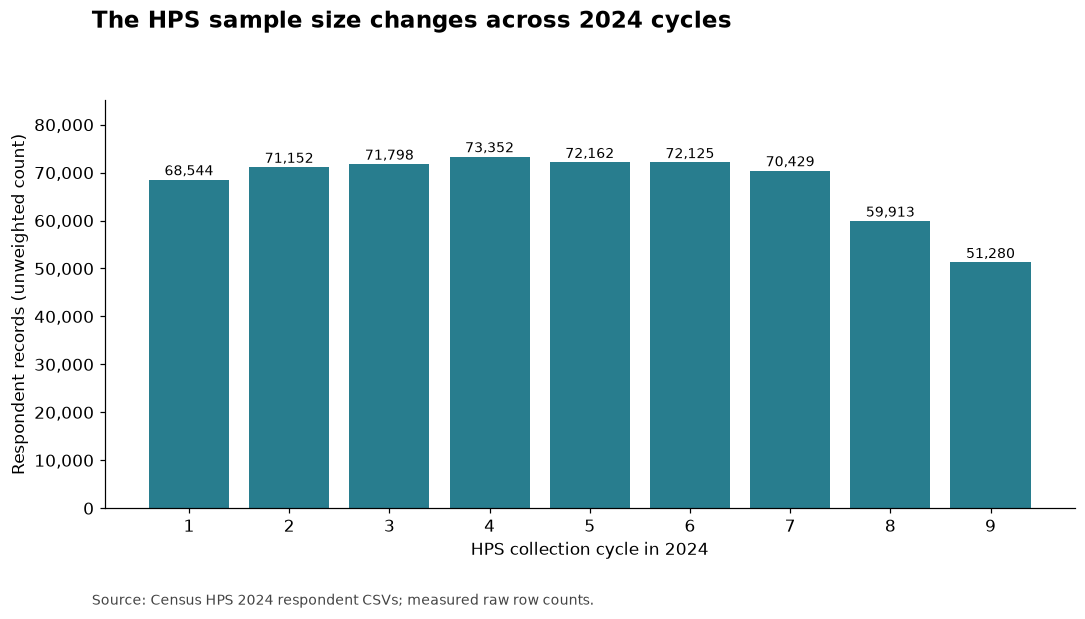

**Observation:** The nine cycles contain 610,755 respondent records. Cycle 9 has 51,280, compared with 68,544 in Cycle 1. These are survey sample sizes, not changes in the number of adults in the population.

In [6]:
# Chart 1 — overview of the raw survey, not a population trend.
fig, ax = plt.subplots()
ax.bar(raw_counts.cycle, raw_counts.raw_rows, color="#287D8E")
ax.set(xlabel="HPS collection cycle in 2024", ylabel="Respondent records (unweighted count)", xticks=range(1,10))
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
for row in raw_counts.itertuples():
    ax.text(row.cycle, row.raw_rows+900, f"{row.raw_rows:,}", ha="center", fontsize=9)
ax.set_ylim(0, raw_counts.raw_rows.max()*1.16)
first_n = int(raw_counts.loc[raw_counts.cycle.eq(1),"raw_rows"].iloc[0])
last_n = int(raw_counts.loc[raw_counts.cycle.eq(9),"raw_rows"].iloc[0])
caption = (f"The nine cycles contain {int(raw_counts.raw_rows.sum()):,} respondent records. "
           f"Cycle 9 has {last_n:,}, compared with {first_n:,} in Cycle 1. "
           "These are survey sample sizes, not changes in the number of adults in the population.")
finish_chart(fig, "01_sample_overview", "The HPS sample size changes across 2024 cycles", caption,
             "Source: Census HPS 2024 respondent CSVs; measured raw row counts.")


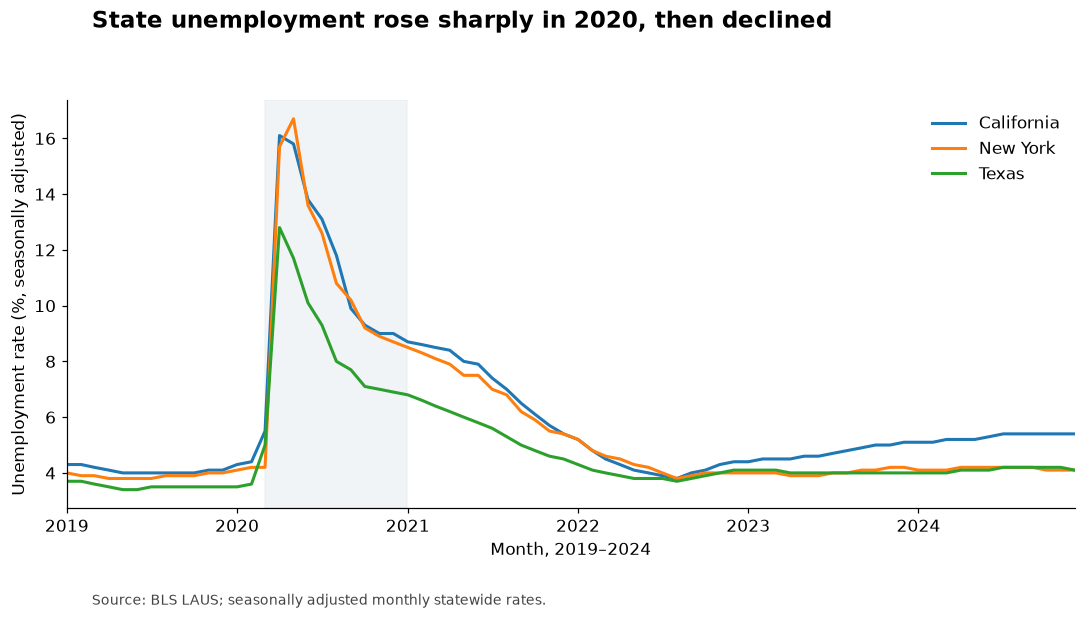

**Observation:** The selected states' 2020 peaks were California 16.1% (Apr); New York 16.7% (May); Texas 12.8% (Apr). The shaded area marks March–December 2020; the timing alone does not identify a causal effect.

In [7]:
# Chart 2 — monthly seasonally adjusted rates for selected states.
fig, ax = plt.subplots()
timeline = monthly.loc[monthly.seasonal.eq("S") & monthly.state_fips.isin(TIMELINE_STATES)].sort_values("date")
peak_notes=[]
for state in TIMELINE_STATES:
    data=timeline.loc[timeline.state_fips.eq(state)]
    ax.plot(data.date, data.unemployment_rate_pct, label=state_names[state], linewidth=2)
    pandemic=data.loc[data.year.eq(2020)]
    peak=pandemic.loc[pandemic.unemployment_rate_pct.idxmax()]
    peak_notes.append(f"{state_names[state]} {peak.unemployment_rate_pct:.1f}% ({peak.date:%b})")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-12-31"), color="#DDE5EA", alpha=.4)
ax.set(xlabel="Month, 2019–2024", ylabel="Unemployment rate (%, seasonally adjusted)")
ax.set_xlim(timeline.date.min(), timeline.date.max())
ax.legend(frameon=False, loc="upper right")
caption="The selected states' 2020 peaks were " + "; ".join(peak_notes) + ". The shaded area marks March–December 2020; the timing alone does not identify a causal effect."
finish_chart(fig, "02_unemployment_timeline", "State unemployment rose sharply in 2020, then declined", caption,
             "Source: BLS LAUS; seasonally adjusted monthly statewide rates.")


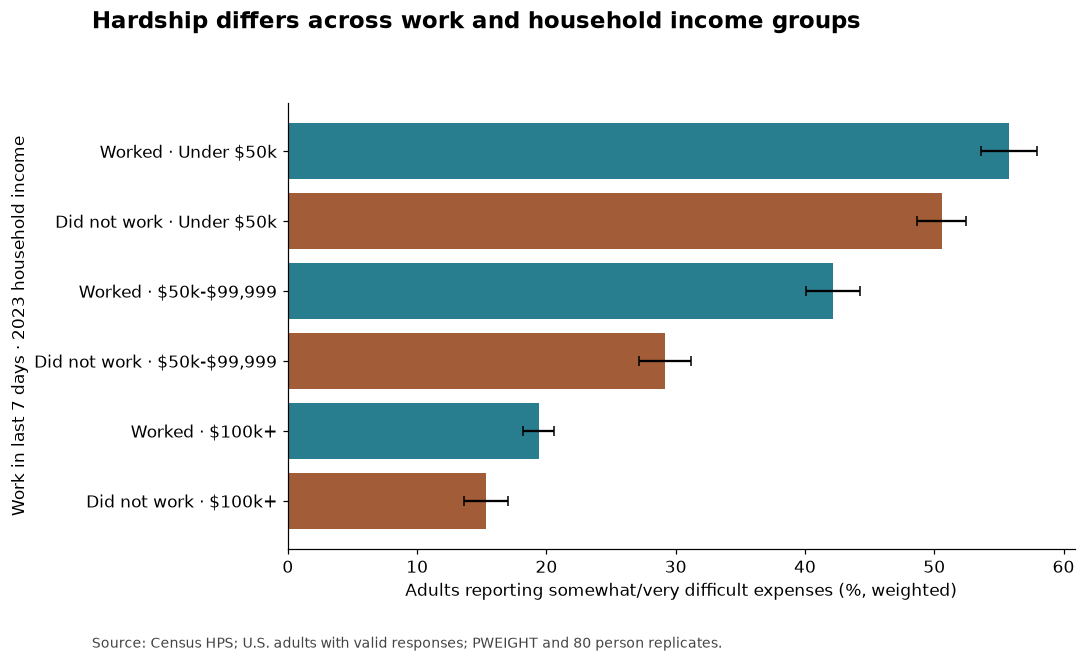

**Observation:** In Cycle 9 (2024-08-20 to 2024-09-16), the highest displayed hardship estimate is 55.8% for Worked in last 7 days / Under $50k. Income is the prior year's household income; did not work is broader than unemployment. Error bars show 90% intervals.

In [8]:
# Chart 3 — work and income groups, national adult-weighted estimates.
data=hps.loc[hps.state_fips.eq("US") & hps.cycle.eq(FOCUS_CYCLE) & hps.dimension.eq("work_income")].copy()
ordered=[f"{work} / {income}" for income in ["Under $50k","$50k-$99,999","$100k+"]
         for work in ["Worked in last 7 days","Did not work in last 7 days"]]
data=data.set_index("group").reindex(ordered).reset_index()
check("chart 3 available estimates", data.hardship_pct.notna().all(), len(data))
labels=[group.replace("Worked in last 7 days / ","Worked · ").replace("Did not work in last 7 days / ","Did not work · ") for group in data.group]
fig, ax=plt.subplots(figsize=(10,6))
colors=["#287D8E" if group.startswith("Worked") else "#A25C38" for group in data.group]
ax.barh(labels, data.hardship_pct, xerr=errorbar_limits(data,"hardship"), color=colors, capsize=3)
ax.invert_yaxis()
ax.set(xlabel="Adults reporting somewhat/very difficult expenses (%, weighted)", ylabel="Work in last 7 days · 2023 household income")
largest=data.loc[data.hardship_pct.idxmax()]
caption=(f"In {cycle_label}, the highest displayed hardship estimate is {largest.hardship_pct:.1f}% for {largest.group}. "
         "Income is the prior year's household income; did not work is broader than unemployment. Error bars show 90% intervals.")
finish_chart(fig,"03_work_income_hardship","Hardship differs across work and household income groups",caption,
             "Source: Census HPS; U.S. adults with valid responses; PWEIGHT and 80 person replicates.")


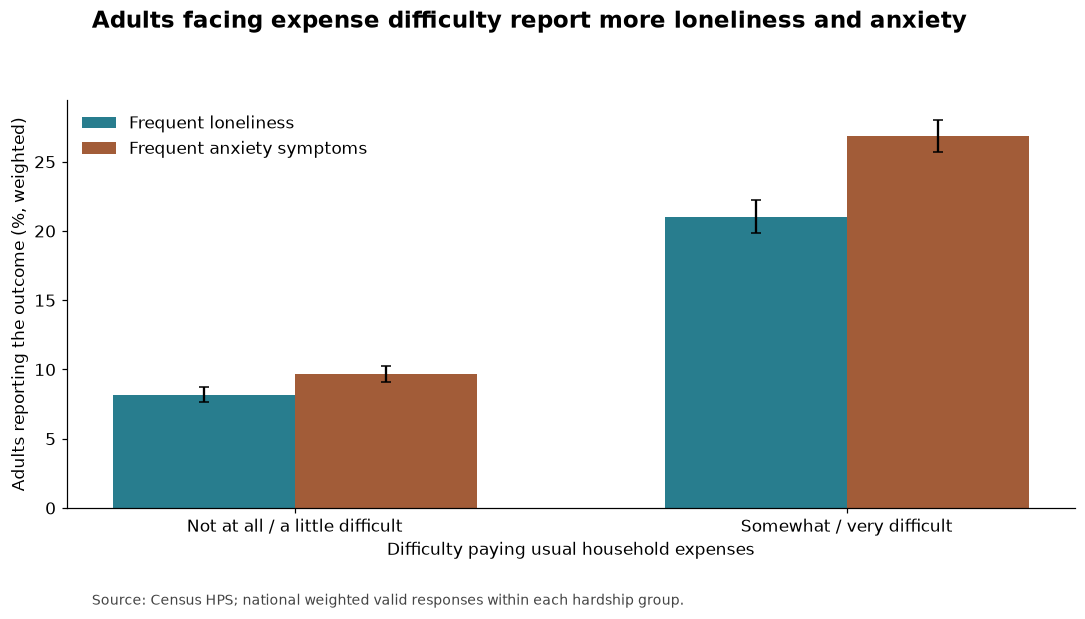

**Observation:** In Cycle 9 (2024-08-20 to 2024-09-16), frequent loneliness is 21.0% in the harder-to-pay group versus 8.2% in the other group; frequent anxiety symptoms are 26.9% versus 9.7%. These are descriptive comparisons, with 90% intervals; they do not show that hardship caused either outcome.

In [9]:
# Chart 4 — compare loneliness and anxiety within hardship groups.
labels=["Not at all/a little difficult","Somewhat/very difficult"]
data=hps.loc[hps.state_fips.eq("US") & hps.cycle.eq(FOCUS_CYCLE) & hps.dimension.eq("hardship")].set_index("group").loc[labels]
check("chart 4 available estimates", data[["lonely_pct","frequent_anxiety_pct"]].notna().all().all(), len(data))
fig, ax=plt.subplots()
x=np.arange(2); width=.33
for shift,metric,name,color in [(-width/2,"lonely","Frequent loneliness","#287D8E"),
                              (width/2,"frequent_anxiety","Frequent anxiety symptoms","#A25C38")]:
    ax.bar(x+shift, data[metric+"_pct"], width, yerr=errorbar_limits(data,metric), label=name, color=color, capsize=3)
ax.set(xticks=x,xticklabels=["Not at all / a little difficult","Somewhat / very difficult"],
       xlabel="Difficulty paying usual household expenses",ylabel="Adults reporting the outcome (%, weighted)")
ax.legend(frameon=False)
caption=(f"In {cycle_label}, frequent loneliness is {data.loc[labels[1],'lonely_pct']:.1f}% in the harder-to-pay group versus "
         f"{data.loc[labels[0],'lonely_pct']:.1f}% in the other group; frequent anxiety symptoms are "
         f"{data.loc[labels[1],'frequent_anxiety_pct']:.1f}% versus {data.loc[labels[0],'frequent_anxiety_pct']:.1f}%. "
         "These are descriptive comparisons, with 90% intervals; they do not show that hardship caused either outcome.")
finish_chart(fig,"04_hardship_social_outcomes","Adults facing expense difficulty report more loneliness and anxiety",caption,
             "Source: Census HPS; national weighted valid responses within each hardship group.")


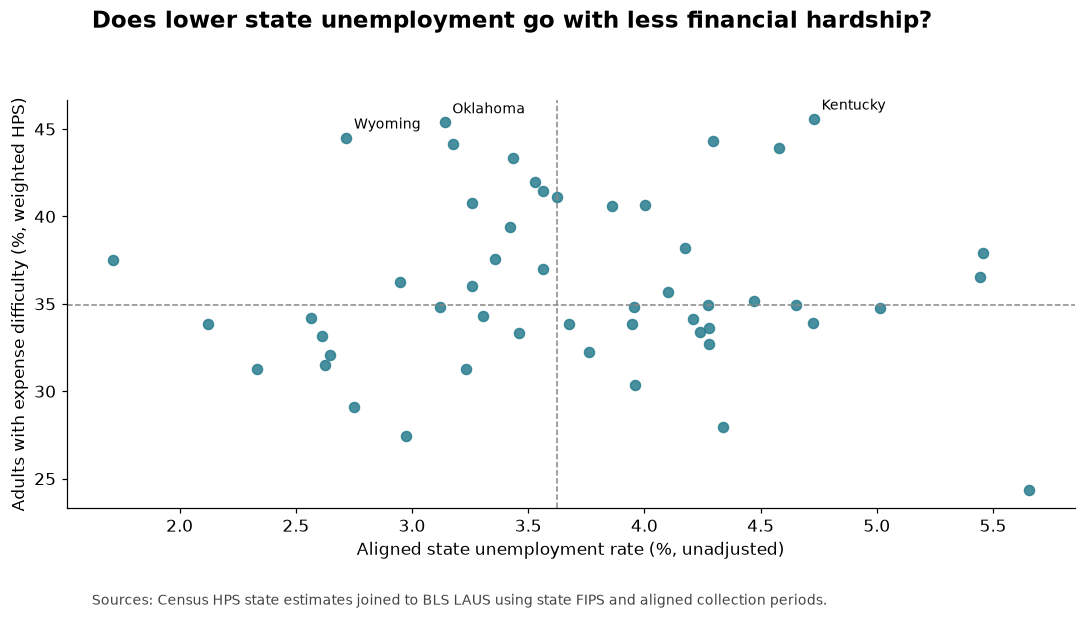

**Observation:** Across 51 jurisdictions in Cycle 9 (2024-08-20 to 2024-09-16), the descriptive Spearman rank association is 0.10. Using the midpoint month instead gives 0.13. Dashed lines are state medians, not official thresholds. Each dot is a state or D.C.; the relationship is ecological and its sampling uncertainty is not shown here.

In [10]:
# Chart 5 — a genuine cross-source state comparison.
scatter=joined.loc[joined.cycle.eq(FOCUS_CYCLE)].copy()
scatter=scatter.dropna(subset=["hardship_pct","laus_aligned_unemployment_rate_pct"])
check("chart 5 state count", len(scatter)==51, len(scatter))
rho=float(scatter.hardship_pct.rank().corr(scatter.laus_aligned_unemployment_rate_pct.rank()))
midpoint_rho=float(scatter.hardship_pct.rank().corr(scatter.laus_midpoint_unemployment_rate_pct.rank()))
fig, ax=plt.subplots()
ax.scatter(scatter.laus_aligned_unemployment_rate_pct,scatter.hardship_pct,s=43,color="#287D8E",alpha=.85)
ax.axhline(scatter.hardship_pct.median(),linestyle="--",linewidth=1,color="#888888")
ax.axvline(scatter.laus_aligned_unemployment_rate_pct.median(),linestyle="--",linewidth=1,color="#888888")
for row in scatter.nlargest(3,"hardship_pct").itertuples():
    ax.annotate(row.state_name,(row.laus_aligned_unemployment_rate_pct,row.hardship_pct),xytext=(5,6),textcoords="offset points",fontsize=9)
ax.set(xlabel="Aligned state unemployment rate (%, unadjusted)",
       ylabel="Adults with expense difficulty (%, weighted HPS)")
caption=(f"Across {len(scatter)} jurisdictions in {cycle_label}, the descriptive Spearman rank association is {rho:.2f}. "
         f"Using the midpoint month instead gives {midpoint_rho:.2f}. Dashed lines are state medians, not official thresholds. "
         "Each dot is a state or D.C.; the relationship is ecological and its sampling uncertainty is not shown here.")
finish_chart(fig,"05_state_unemployment_hardship","Does lower state unemployment go with less financial hardship?",caption,
             "Sources: Census HPS state estimates joined to BLS LAUS using state FIPS and aligned collection periods.")


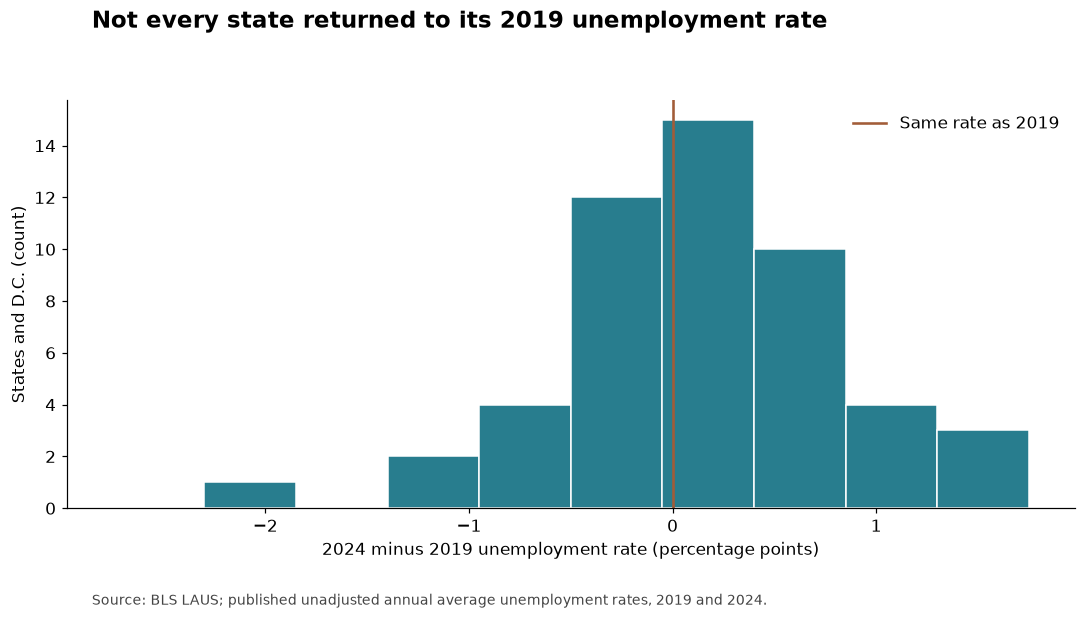

**Observation:** 21 of 51 jurisdictions had a published 2024 annual unemployment rate at or below their 2019 rate. Changes range from -2.3 to +1.4 percentage points. A recovered rate does not mean every household recovered; each state has equal weight in this histogram.

In [11]:
# Chart 6 — distribution of changes in the published annual unemployment rate.
recovery=annual.pivot(index=["state_fips","state_name"],columns="year",values="unemployment_rate_pct").reset_index()
recovery["change_2019_2024_pp"]=recovery[2024]-recovery[2019]
recovered_n=int(recovery.change_2019_2024_pp.le(0).sum())
fig, ax=plt.subplots()
edges=np.linspace(np.floor(recovery.change_2019_2024_pp.min()*2)/2-.25,
                  np.ceil(recovery.change_2019_2024_pp.max()*2)/2+.25,11)
ax.hist(recovery.change_2019_2024_pp,bins=edges,color="#287D8E",edgecolor="white")
ax.axvline(0,color="#A25C38",linewidth=1.7,label="Same rate as 2019")
ax.set(xlabel="2024 minus 2019 unemployment rate (percentage points)",ylabel="States and D.C. (count)")
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
ax.legend(frameon=False)
caption=(f"{recovered_n} of 51 jurisdictions had a published 2024 annual unemployment rate at or below their 2019 rate. "
         f"Changes range from {recovery.change_2019_2024_pp.min():+.1f} to {recovery.change_2019_2024_pp.max():+.1f} percentage points. "
         "A recovered rate does not mean every household recovered; each state has equal weight in this histogram.")
finish_chart(fig,"06_recovery_distribution","Not every state returned to its 2019 unemployment rate",caption,
             "Source: BLS LAUS; published unadjusted annual average unemployment rates, 2019 and 2024.")
recovery.rename(columns={year:f"unemployment_rate_{year}_pct" for year in range(2019,2025)}).to_csv(RESULTS/"state_recovery_2019_2024.csv",index=False)
pd.DataFrame(chart_records).to_csv(RESULTS/"chart_captions.csv",index=False)


### 11 Drill down and prepare the stakeholder questions

The six charts provide the first briefing. The table below supports our fifth question: does the national age pattern hold within a state? Change `FOCUS_STATE` and `FOCUS_CYCLE` in the first code cell, then rerun this cell (and chart cells if you change the cycle). A missing percentage with `suppressed=True` means the group failed our reliability rule.

Our five questions now have concrete tables behind them:

1. **Recovery over time:** Which states returned to their 2019 annual unemployment rate by 2024, and how did their monthly paths differ?
2. **Joined state comparison:** In each 2024 cycle, do states with lower unemployment also have less reported expense difficulty?
3. **Work and income:** How does hardship differ between work groups within the three income bands?
4. **Social outcomes:** How do frequent loneliness and anxiety symptoms differ between hardship groups?
5. **Drill-down:** How do loneliness and lack of support differ across age groups, and does the national pattern hold within a state?

These questions are descriptive. The scatterplot's correlation is exploratory; it is not a causal estimate or a significance test. A state rate is not a demographic unemployment rate. Individual outcomes do not establish household trajectories. The sample changes between cycles.


In [12]:
age_view=hps.loc[hps.state_fips.isin(["US",FOCUS_STATE]) & hps.cycle.eq(FOCUS_CYCLE) & hps.dimension.eq("age")].copy()
age_view["location"]=age_view.state_fips.map({"US":"United States",FOCUS_STATE:state_names[FOCUS_STATE]})
age_columns=["location","group","sample_n","lonely_valid_n","lonely_pct","lonely_ci90_lower","lonely_ci90_upper",
             "lonely_suppressed","lack_support_pct","lack_support_suppressed"]
display(age_view[age_columns].sort_values(["location","group"]).round(2))
age_view[age_columns].to_csv(RESULTS/"age_drilldown_selected.csv",index=False)
display(recovery[["state_name",2019,2024,"change_2019_2024_pp"]].sort_values("change_2019_2024_pp").head(8))


,location,group,sample_n,lonely_valid_n,lonely_pct,lonely_ci90_lower,lonely_ci90_upper,lonely_suppressed,lack_support_pct,lack_support_suppressed
8055,New York,18-34,128,124,11.91,7.02,16.80,False,39.11,False
8056,New York,35-64,514,504,11.92,8.08,15.77,False,49.41,False
8057,New York,65+,250,247,6.99,3.46,10.53,False,37.06,False
7956,United States,18-34,6268,6045,21.20,19.84,22.57,False,47.90,False
7957,United States,35-64,27604,27006,12.42,11.77,13.08,False,44.23,False
7958,United States,65+,17408,17064,6.23,5.68,6.78,False,26.93,False


year,state_name,2019,2024,change_2019_2024_pp
24,Mississippi,5.5,3.2,-2.3
1,Alaska,5.6,4.5,-1.1
2,Arizona,4.8,3.7,-1.1
31,New Mexico,5.0,4.1,-0.9
41,South Dakota,2.7,1.8,-0.9
48,West Virginia,4.9,4.1,-0.8
50,Wyoming,3.7,3.1,-0.6
26,Montana,3.5,3.0,-0.5


### 12 Export the briefing pack and hand off to the team

The export includes the six chart images with their observations in a readable HTML briefing, aggregate data, cleaning decisions, row counts, validation results, input fingerprints, a variable dictionary, and the 20-case automated check summary. It excludes `raw` and `private_checks`.

The HTML briefing can be opened in a browser without a server. The ZIP is the package to share with teammates or a stakeholder role-play. Before submission, a teammate should review the cleaning log and private 20-case comparison. Record that review honestly; this notebook does not mark it complete for you.

**Team checkpoint:** Agree on the small-group rule, inspect state outliers, examine the alignment sensitivity, and note any conclusions that change. Confidence intervals here describe sampling uncertainty; they do not remove nonresponse, measurement, income-reference-year, or model biases. Overlapping intervals are not a formal test of a difference.


In [13]:
import html, base64, shutil
from collections import Counter
write_logs()
variable_rows=[]
for metric,(variable,valid,yes) in METRICS.items():
    variable_rows.append(dict(source="Census HPS",column=variable,derived_measure=metric,
                              valid_codes=str(valid),qualifying_codes=str(yes),unit="weighted percent of adults with valid responses"))
pd.DataFrame(variable_rows).to_csv(RESULTS/"outcome_dictionary.csv",index=False)
run_summary={
    "raw_hps_rows":int(raw_counts.raw_rows.sum()),"selected_bls_nsa_long_rows":selected_nsa,
    "combined_raw_rows_without_double_counting_adjusted_version":raw_total,
    "hps_aggregate_rows":len(hps),"bls_monthly_rows":len(monthly),"bls_annual_rows":len(annual),
    "joined_rows":len(joined),"unmatched_left":int(left_unmatched),"unmatched_right":int(right_unmatched),
    "automated_spotcheck_cases":len(spotcheck),"automated_spotcheck_passed":int(spotcheck.all_passed.sum()),
    "manual_team_review":"Pending","cleaning_decisions":len(cleaning_log),
    "validation_checks":len(checks),"validation_failures":sum(not row["passed"] for row in checks),
    "charts":len(chart_records),"focus_cycle":FOCUS_CYCLE,
    "state_spearman_descriptive":rho,"midpoint_spearman_descriptive":midpoint_rho,
    "max_alignment_difference_pp":float(joined.alignment_difference_pp.abs().max()),
    "jurisdictions_rate_at_or_below_2019":recovered_n,
    "runtime":"local Python when validated by the author; rerun in your own Colab session",
    "versions":{"python":sys.version.split()[0],"numpy":np.__version__,"pandas":pd.__version__,"matplotlib":matplotlib.__version__}}
(RESULTS/"run_summary.json").write_text(json.dumps(run_summary,indent=2),encoding="utf-8")

# Guard the public data exports. Internal same-survey IDs never leave private processing.
for path in RESULTS.glob("*.csv"):
    columns=pd.read_csv(path,nrows=0).columns
    forbidden={"SCRAM","SCRAMID","TBIRTH_YEAR","ABIRTH_YEAR","EST_MSA","respondent_id","raw_row_position"}
    check("privacy export "+path.name, not bool(set(columns)&forbidden), "no forbidden respondent fields")
check("six briefing charts",len(chart_records)==6,len(chart_records))
write_logs()
run_summary["validation_checks"]=len(checks)
(RESULTS/"run_summary.json").write_text(json.dumps(run_summary,indent=2),encoding="utf-8")

brief=["<!doctype html><html lang='en'><meta charset='utf-8'><meta name='viewport' content='width=device-width'>",
       "<title>COVID recovery Step 0 briefing</title><style>body{font:17px/1.55 system-ui;max-width:1050px;margin:36px auto;padding:0 20px;color:#172b35}img{width:100%;height:auto}section{margin:42px 0}h1,h2{line-height:1.2}small{color:#47545b}table{border-collapse:collapse}td,th{border:1px solid #ccc;padding:8px}</style>",
       "<h1>COVID recovery and household well-being</h1><p>Step 0 briefing for stakeholder discussion</p>",
       f"<p>We processed <b>{int(raw_counts.raw_rows.sum()):,}</b> HPS respondent records and joined <b>{len(joined)}</b> state-cycle summaries to BLS with no unmatched keys. HPS covers January–September 2024; the BLS recovery timeline covers 2019–2024.</p>",
       "<p>Employment figures and household experiences can move differently. The charts below describe the observed patterns. They do not establish that COVID, unemployment, or hardship caused a person's loneliness or anxiety.</p>"]
for chart in chart_records:
    encoded=base64.b64encode((RESULTS/"charts"/chart["file"]).read_bytes()).decode()
    brief.append(f"<section><h2>{html.escape(chart['title'])}</h2><img alt='{html.escape(chart['title'],quote=True)}' src='data:image/png;base64,{encoded}'><p>{html.escape(chart['caption'])}</p><small>{html.escape(chart['source'])}</small></section>")
brief.append("<h2>What to question before writing the story</h2><ul><li>Which groups are missing or suppressed, and could nonresponse change the comparison?</li><li>Does using a midpoint month change the state relationship?</li><li>Does the national age pattern hold in the selected state?</li><li>Could a low unemployment rate coexist with high hardship because of wages, prices, work hours, or household circumstances that these charts do not isolate?</li></ul>")
brief.append("<h2>Methods and limits</h2><p>HPS uses person weights and 80 person replicate weights. Error bars show 90% intervals. Percentages exclude invalid answers per outcome. We suppress estimates below valid n=100 or Kish effective n=30. This project rule is not an official certification. Income is 2023 household income; work means any paid/profit work in the last seven days. Broad ages are approximate. The surveys do not follow the same people over time. BLS state estimates are modeled and revised. State relationships are ecological and descriptive.</p>")
brief.append("<p>AI helped acquire and inspect files, write and run preparation code, generate the charts, and draft this notebook. The run records automated checks and 20 raw-to-processed comparisons. Human team review and stakeholder interviews remain pending; no stakeholder dialogue has been fabricated.</p><h2>Original sources</h2><ul>")
for label,url in SOURCE_LINKS.items():
    brief.append(f"<li><a href='{html.escape(url,quote=True)}'>{html.escape(label)}</a></li>")
brief.append("</ul></html>")
(RESULTS/"briefing_pack.html").write_text("\n".join(brief),encoding="utf-8")
(RESULTS/"README.txt").write_text(
    "Open briefing_pack.html first. It embeds all six chart images.\n"
    "Aggregates use person weights; percentages are 0–100; SEs are percentage points.\n"
    "Do not sum overlapping demographic views. Do not average state percentages into a national estimate.\n"
    "Definitional combinations (hardship within hardship group, support within support group) are not research findings.\n"
    "The cleaning log's affected counts overlap across issues and variables.\n"
    "20 spot-checks were automated. Human review of private_checks/spotcheck_20_raw_vs_processed.csv is pending.\n"
    "Raw files and the private table are intentionally excluded. No dashboard or stakeholder interview is included.\n",encoding="utf-8")
bundle=BASE/"COVID_Step0_Briefing_Pack.zip"
with zipfile.ZipFile(bundle,"w",compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(RESULTS.rglob("*")):
        if path.is_file():
            archive.write(path,path.relative_to(RESULTS))
print("Briefing:",RESULTS/"briefing_pack.html")
print("Download this ZIP:",bundle)
print(f"{len(checks)} checks passed; {len(cleaning_log)} cleaning decisions; six charts; 20 automated comparisons.")
display(pd.Series(run_summary,name="Run results").to_frame())


216 checks passed; 208 cleaning decisions; six charts; 20 automated comparisons.


,Run results
raw_hps_rows,610755
selected_bls_nsa_long_rows,15912
combined_raw_rows_without_double_counting_adjusted_version,626667
hps_aggregate_rows,8892
bls_monthly_rows,7344
bls_annual_rows,306
joined_rows,459
unmatched_left,0
unmatched_right,0
automated_spotcheck_cases,20


### 13 Download your work and review it together

In Colab's Files panel, open the project folder, find **COVID_Step0_Briefing_Pack.zip**, click its three-dot menu, and choose **Download**. Also save the notebook with **File → Download → Download .ipynb**. If you used Drive, the files remain there after the runtime disconnects.

For a 3–4 person team, one person can review acquisition and row counts, one can review missingness/weights and the private 20-row comparison, one can read the charts for misleading labels or conclusions, and one can assemble the stakeholder briefing. With three people, combine the last two roles.

Before the stakeholder round, write down: **what the charts show, what remains uncertain, and what decision a stakeholder might make**. Start the discussion with the exported briefing. Record real stakeholder-role-play questions and your answers in the next assignment step; that conversation has not happened in this notebook.

**AI-use note:** AI drafted and executed this preparation notebook against the audited local source files. The notebook makes its code, source versions, assumptions, and automated checks visible. The team still needs to run it in its own Colab session, inspect the results, manually review the 20 cases, and approve its interpretation. No human review or Colab cloud execution is claimed merely because the local run passed.
